# Boat tracks Sisal port

Heatmap, track map and number of boats entering/leaving the port, from the ship tracker output (s model).

The CSV files are in `s_model_csv/<date>/` (copied from the Drive folder `MDP recording`). Some days also have a `_clean` or `_edited` file, `RUNS` sets which file is used.

1. Settings
2. Load the runs
3. Heatmap
4. Track map
5. Boats entering and leaving the port

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx
import cv2
from scipy.ndimage import gaussian_filter

## 1. Settings

In [2]:
CSV_DIR = "s_model_csv"                 # tracker output (s model)
DRIVE = r"G:\My Drive\MDP recording"    # only for the videos in section 5

# (date, camera, csv file)
RUNS = [
    ("2026-09-15", "P1", "s_P1_RAW_15-09_0530-1830.csv"),
    ("2026-09-21", "P1", "s_P1_RAW_21-09_0530-1830.csv"),
    ("2026-09-23", "P2", "s_P2_RAW_23-09_0530-1830.csv"),
    ("2026-09-24", "P2", "s_P2_RAW_24-09_0530-1830.csv"),
    ("2026-09-25", "P2", "s_P2_RAW_25-09_0530-1830.csv"),
    ("2026-09-26", "P2", "s_P2_RAW_26-09_0530-1830.csv"),
    ("2026-09-27", "P2", "s_P2_RAW_27-09_0530-1830.csv"),
    ("2026-09-28", "P2", "s_P2_RAW_28-09_0530-1830.csv"),
    ("2026-10-12", "P4L", "s_P4L_RAW_12-10_0530-1830_6fps.csv"),
    ("2026-10-13", "P4L", "s_P4L_RAW_13-10_0530-1830_6fps.csv"),
    ("2026-10-14", "P4L", "s_P4L_RAW_14-10_0530-1830_6fps.csv"),
    ("2026-10-15", "P4L", "s_P4L_RAW_15-10_0530-1830_6fps.csv"),
    ("2026-10-16", "P4L", "s_P4L_RAW_16-10_0530-1830_6fps.csv"),
    ("2026-10-17", "P4L", "s_P4L_RAW_17-10_0530-1830_6fps.csv"),
    ("2026-10-12", "P4R", "s_P4R_RAW_12-10_0530-1830_6fps.csv"),
    ("2026-10-13", "P4R", "s_P4R_RAW_13-10_0530-1830_6fps.csv"),
    ("2026-10-14", "P4R", "s_P4R_RAW_14-10_0530-1830_6fps.csv"),
    ("2026-10-15", "P4R", "s_P4R_RAW_15-10_0530-1830_6fps.csv"),
    ("2026-10-16", "P4R", "s_P4R_RAW_16-10_0530-1830_6fps.csv"),
    ("2026-10-17", "P4R", "s_P4R_RAW_17-10_0530-1830_6fps.csv"),
    ("2026-10-28", "P5", "s_P5_RAW_28-10_0530-1800_6fps.csv"),
    ("2026-10-29", "P5", "s_P5_RAW_29-10_0530-1800_6fps.csv"),
]

# shift per camera in m (east, north)
SHIFT_M = {
    "P1": (-18, -3),
    "P2": (0, 0),
    "P4L": (-10.74, -7.53),
    "P4R": (0, 0),
    "P5": (-12.7, -4.8),
}

VIDEO_FPS = 12
MIN_CONF = 0.30

# drone orthomosaic, plotted on top of the satellite image
DRONE_TIF = r"C:\Users\apper\MDP_CameraLocalRuns\Drone footage\20261007_Canal_transparent_mosaic_group1 (1).tif"
DRONE_PIXEL_M = 0.25

## 2. Load the runs
The 6 fps runs only have every second frame, so they get `weight = 2` in the heatmap.

In [3]:
def load_run(date, camera, file):
    path = os.path.join(CSV_DIR, date, file)
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print("missing or empty:", path)
        return None

    df = pd.read_csv(path)
    df = df[df["conf"] >= MIN_CONF].dropna(subset=["lat", "lon"])
    df["date"] = date
    df["camera"] = camera

    # video starts at the time in the file name (..._0530-1830 -> 05:30)
    start = file.split("_")[4][:4]
    t0 = pd.Timestamp(f"{date} {start[:2]}:{start[2:]}")
    df["time"] = t0 + pd.to_timedelta(df["frame"] / VIDEO_FPS, unit="s")

    df["weight"] = 2 if (df["frame"] % 2 == 0).all() else 1

    east, north = SHIFT_M[camera]
    df["lat"] = df["lat"] + north / 111320
    df["lon"] = df["lon"] + east / (111320 * np.cos(np.radians(df["lat"])))

    print(date, camera, len(df), "detections,", df.loc[df.track_id >= 0, "track_id"].nunique(), "tracks")
    return df


data = pd.concat([load_run(*run) for run in RUNS])
print("total:", len(data))

2026-09-15 P1 73933 detections, 693 tracks
2026-09-21 P1 29441 detections, 282 tracks


2026-09-23 P2 90779 detections, 1037 tracks


2026-09-24 P2 97353 detections, 1160 tracks


2026-09-25 P2 88365 detections, 1050 tracks


2026-09-26 P2 131680 detections, 1197 tracks


2026-09-27 P2 69930 detections, 477 tracks


... (8 outputs left out)

2026-10-13 P4R 19591 detections, 347 tracks
2026-10-14 P4R 21090 detections, 269 tracks


2026-10-15 P4R 19535 detections, 383 tracks
2026-10-16 P4R 16477 detections, 304 tracks


2026-10-17 P4R 13584 detections, 306 tracks
2026-10-28 P5 25164 detections, 186 tracks


2026-10-29 P5 1830 detections, 16 tracks
total: 1186888


## 3. Heatmap

In [4]:
def to_map_xy(lat, lon):
    # lat/lon to web mercator, same as the satellite tiles
    R = 6378137
    x = R * np.radians(lon)
    y = R * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))
    return x, y


def satellite(w, s, e, n):
    google = "https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}"
    esri = ctx.providers.Esri.WorldImagery
    for src, zoom in [(google, 19), (google, 18), (esri, 18), (esri, 17)]:
        try:
            img, extent = ctx.bounds2img(w, s, e, n, zoom=zoom, source=src)
            if img[..., :3].std() > 10:     # grey "no imagery" tiles
                return img, extent
        except Exception as err:
            print("basemap failed:", err)
    return None, None


def drone_photo(tif, pixel_m):
    # reading the tif takes ~1 min, so it is saved as an npz the first time
    # (delete the npz when the photo or DRONE_PIXEL_M changes)
    cache = f"drone_background_{pixel_m}m.npz"
    if os.path.exists(cache):
        saved = np.load(cache)
        return saved["img"], tuple(saved["extent"])
    if not os.path.exists(tif):
        print("drone photo not found:", tif)
        return None, None

    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling
    with rasterio.open(tif) as src, WarpedVRT(src, crs="EPSG:3857") as vrt:
        left, bottom, right, top = vrt.bounds
        rows, cols = int((top - bottom) / pixel_m), int((right - left) / pixel_m)
        img = vrt.read(out_shape=(vrt.count, rows, cols), resampling=Resampling.average)
    img = np.moveaxis(img, 0, -1)
    extent = (left, right, bottom, top)
    np.savez_compressed(cache, img=img, extent=extent)
    return img, extent


data["x"], data["y"] = to_map_xy(data["lat"].to_numpy(), data["lon"].to_numpy())

pad = 60    # m
w, e = data["x"].min() - pad, data["x"].max() + pad
s, n = data["y"].min() - pad, data["y"].max() + pad
background, background_extent = satellite(w, s, e, n)
drone, drone_extent = drone_photo(DRONE_TIF, DRONE_PIXEL_M)

### Cleaning the detections

*This cleaning step was made with AI (Claude).*

Before the heatmap, detections that are probably not moving boats are removed:
- **short tracks**: fewer than `MIN_TRACK_POINTS` detections (flickering false detections)
- **stationary tracks**: the object moves less than `MIN_MOVE_M` metres in total (things on the shore)
- **moored**: the parts of a track where the boat moves slower than `MOORED_SPEED_MS` over `MOORED_WINDOW_S` seconds
  (moored boats, boats waiting at the quay). Without this, one boat lying still all day becomes the "busiest cell"
  of its camera and makes the rest of that camera almost invisible in the per-camera heatmap.
- **jumps**: a position more than `MAX_SPEED_MS` m/s away from the previous one in the same track (bad position, the scattered dots)
- **lonely cells**: map cells visited by fewer than `MIN_TRACKS_PER_CELL` different tracks

In [5]:
# Cleaning step made with AI (Claude)
MIN_TRACK_POINTS = 10      # detections per track
MIN_MOVE_M = 15            # metres a track has to move in total
MOORED_WINDOW_S = 30       # moored check: compare a track's position in blocks of this many seconds
MOORED_SPEED_MS = 0.3      # slower than this (m/s) between neighbouring blocks = lying still
MAX_SPEED_MS = 15          # m/s (about 30 knots); faster jumps are bad positions
MIN_TRACKS_PER_CELL = 2    # different tracks per map cell
CLEAN_CELL_M = 2           # cell size for that last check, in metres

c = data[data["track_id"] >= 0].sort_values(["date", "camera", "track_id", "time"]).copy()
c["track"] = c["date"] + "_" + c["camera"] + "_" + c["track_id"].astype(str)
removed = {"untracked": len(data) - len(c)}

# short and stationary tracks
per_track = c.groupby("track").agg(points=("x", "size"),
                                   dx=("x", lambda v: v.max() - v.min()),
                                   dy=("y", lambda v: v.max() - v.min()))
short = per_track.index[per_track["points"] < MIN_TRACK_POINTS]
still = per_track.index[(per_track["points"] >= MIN_TRACK_POINTS) & (np.hypot(per_track["dx"], per_track["dy"]) < MIN_MOVE_M)]
removed["short tracks"] = c["track"].isin(short).sum()
removed["stationary tracks"] = c["track"].isin(still).sum()
c = c[~c["track"].isin(short) & ~c["track"].isin(still)]

# moored: the parts of a track where the boat lies still (moored, waiting at the quay).
# Split each track into blocks of MOORED_WINDOW_S seconds and take the middle position of each block.
# A block is "lying still" when it is close to both the block before and the block after it.
# Only those parts are removed, so a boat that sails in and then moors keeps its trip.
block = ((c["time"] - c["time"].dt.normalize()).dt.total_seconds() // MOORED_WINDOW_S).astype(int)
centre = c.groupby([c["track"], block])[["x", "y"]].median()
gc = centre.groupby(level=0)
to_prev = np.hypot(gc["x"].diff(), gc["y"].diff())
to_next = np.hypot(gc["x"].diff(-1), gc["y"].diff(-1))
lying_still = pd.concat([to_prev, to_next], axis=1).max(axis=1) < MOORED_SPEED_MS * MOORED_WINDOW_S
moored = lying_still.reindex(pd.MultiIndex.from_arrays([c["track"], block])).fillna(False).to_numpy(dtype=bool)
removed["moored"] = moored.sum()
c = c[~moored]

# jumps: speed from the previous detection of the same track
g = c.groupby("track")
dist = np.hypot(g["x"].diff(), g["y"].diff())
dt = g["time"].diff().dt.total_seconds()
jump = (dist / dt) > MAX_SPEED_MS
removed["jumps"] = jump.sum()
c = c[~jump]

# lonely cells
cell = (((c["x"] - w) // CLEAN_CELL_M).astype(int).astype(str) + "_" + ((c["y"] - s) // CLEAN_CELL_M).astype(int).astype(str))
tracks_in_cell = c.groupby(cell)["track"].transform("nunique")
removed["lonely cells"] = (tracks_in_cell < MIN_TRACKS_PER_CELL).sum()
clean = c[tracks_in_cell >= MIN_TRACKS_PER_CELL]

for why, count in removed.items():
    print(f"removed {count:>9,}  {why}")
print(f"kept    {len(clean):>9,} of {len(data):,} detections ({len(clean) / len(data):.0%})")

removed         6  untracked
removed    12,479  short tracks
removed    88,705  stationary tracks
removed   117,647  moored
removed     8,631  jumps
removed     8,078  lonely cells
kept      951,342 of 1,186,888 detections (80%)


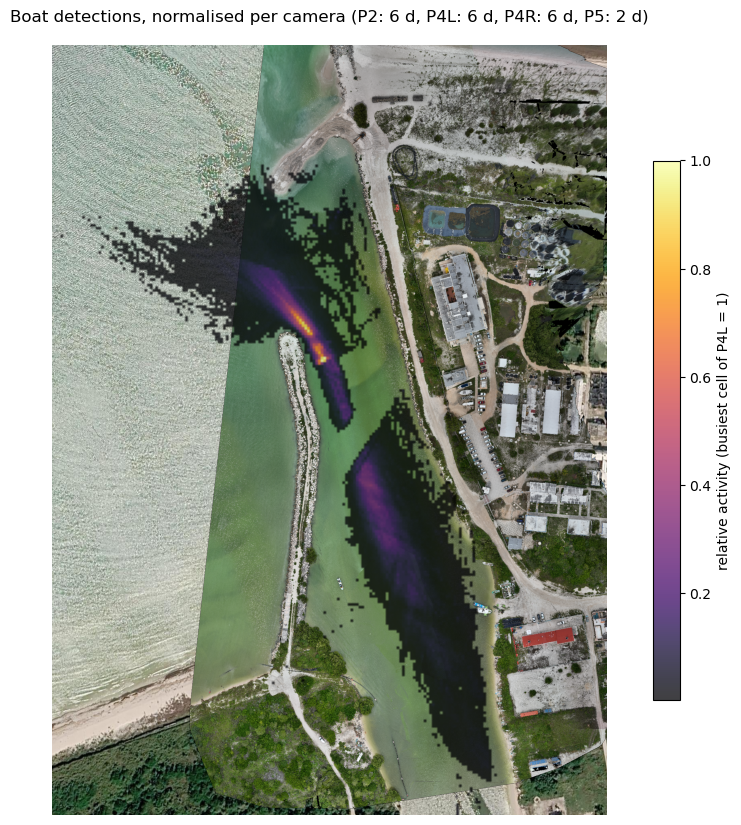

In [6]:
CELL_M = 2          # m
BLUR_CELLS = 0
CAMERAS = ["P2", "P4L", "P4R", "P5"]

# "none": all days added up
# "per_day": divided by the number of days of each camera
# "per_camera": scaled so the busiest cell is 1
NORMALISE = "per_camera"
SAME_SCALE_AS = {"P4R": "P4L", "P2": "P4L", "P5": "P4L"}   # these use the scale of P4L
LEFT_MARGIN_M = 100   # m of sea shown left of the drone photo

xbins = np.arange(w, e + CELL_M, CELL_M)
ybins = np.arange(s, n + CELL_M, CELL_M)


def camera_heatmap(camera):
    d = clean[clean["camera"] == camera]
    if d.empty:
        return None
    Hc, _, _ = np.histogram2d(d["x"], d["y"], bins=[xbins, ybins], weights=d["weight"])
    Hc = gaussian_filter(Hc, BLUR_CELLS).T
    if NORMALISE in ("per_day", "per_camera"):
        Hc = Hc / d["date"].nunique()
    return Hc


H = np.zeros((len(ybins) - 1, len(xbins) - 1))
for camera in CAMERAS:
    Hc = camera_heatmap(camera)
    if Hc is None:
        continue
    if NORMALISE == "per_camera":
        ref = SAME_SCALE_AS.get(camera, camera)
        Href = Hc if ref == camera else camera_heatmap(ref)
        scale = Href.max() if Href is not None else Hc.max()
        H = np.maximum(H, np.clip(Hc / scale, 0, 1))    # overlap: keep the highest
    else:
        H = H + Hc
H[H < H.max() * 0.002] = np.nan     # empty cells transparent

label = {"none": f"detections per {CELL_M} m cell (all days)",
         "per_day": f"detections per {CELL_M} m cell per day",
         "per_camera": "relative activity (busiest cell of P4L = 1)"}[NORMALISE]

fig, ax = plt.subplots(figsize=(12, 10))
if background is not None:
    ax.imshow(background, extent=background_extent)
if drone is not None:
    ax.imshow(drone, extent=drone_extent)
im = ax.imshow(H, extent=(xbins[0], xbins[-1], ybins[0], ybins[-1]), origin="lower", cmap="inferno", alpha=0.75)
if drone is not None:
    ax.set_xlim(max(w, drone_extent[0] - LEFT_MARGIN_M), e)
    ax.set_ylim(drone_extent[2], n)
else:
    ax.set_xlim(w, e)
    ax.set_ylim(s, n)
ax.set_axis_off()
days = clean[clean["camera"].isin(CAMERAS)].groupby("camera")["date"].nunique()
ax.set_title("Boat detections, normalised per camera (" + ", ".join(f"{c}: {days.get(c, 0)} d" for c in CAMERAS) + ")")
fig.colorbar(im, ax=ax, shrink=0.7, label=label)
plt.savefig(f"heatmap_all_runs_{NORMALISE}.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Track map
All tracks, one colour per camera. Used to set `SHIFT_M`: the tracks should lie on the water.

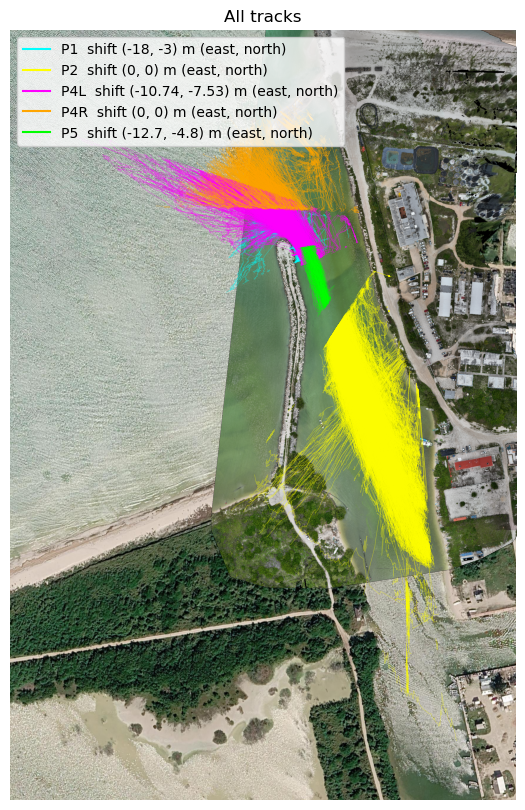

In [7]:
MIN_POINTS = 10
COLORS = {"P1": "cyan", "P2": "yellow", "P4L": "magenta", "P4R": "orange", "P5": "lime"}

fig, ax = plt.subplots(figsize=(12, 10))
if background is not None:
    ax.imshow(background, extent=background_extent)
if drone is not None:
    ax.imshow(drone, extent=drone_extent)

tracks = data[data["track_id"] >= 0]
for (date, camera, track_id), t in tracks.groupby(["date", "camera", "track_id"]):
    if len(t) >= MIN_POINTS:
        ax.plot(t["x"], t["y"], color=COLORS[camera], linewidth=0.5, alpha=0.3)

for camera, color in COLORS.items():
    ax.plot([], [], color=color, label=f"{camera}  shift {SHIFT_M[camera]} m (east, north)")
ax.legend(loc="upper left")
ax.set_xlim(w, e)
ax.set_ylim(s, n)
ax.set_axis_off()
ax.set_title("All tracks")
plt.savefig("tracks_all_runs.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Boats entering and leaving the port
For each camera there is a vertical line in the image (`x` in pixels). A track that starts on one side and ends on the other side has passed the line. Crossing to the right is leaving the port.

The next cell plots the line on a video frame together with one day of detections, to check where it is.

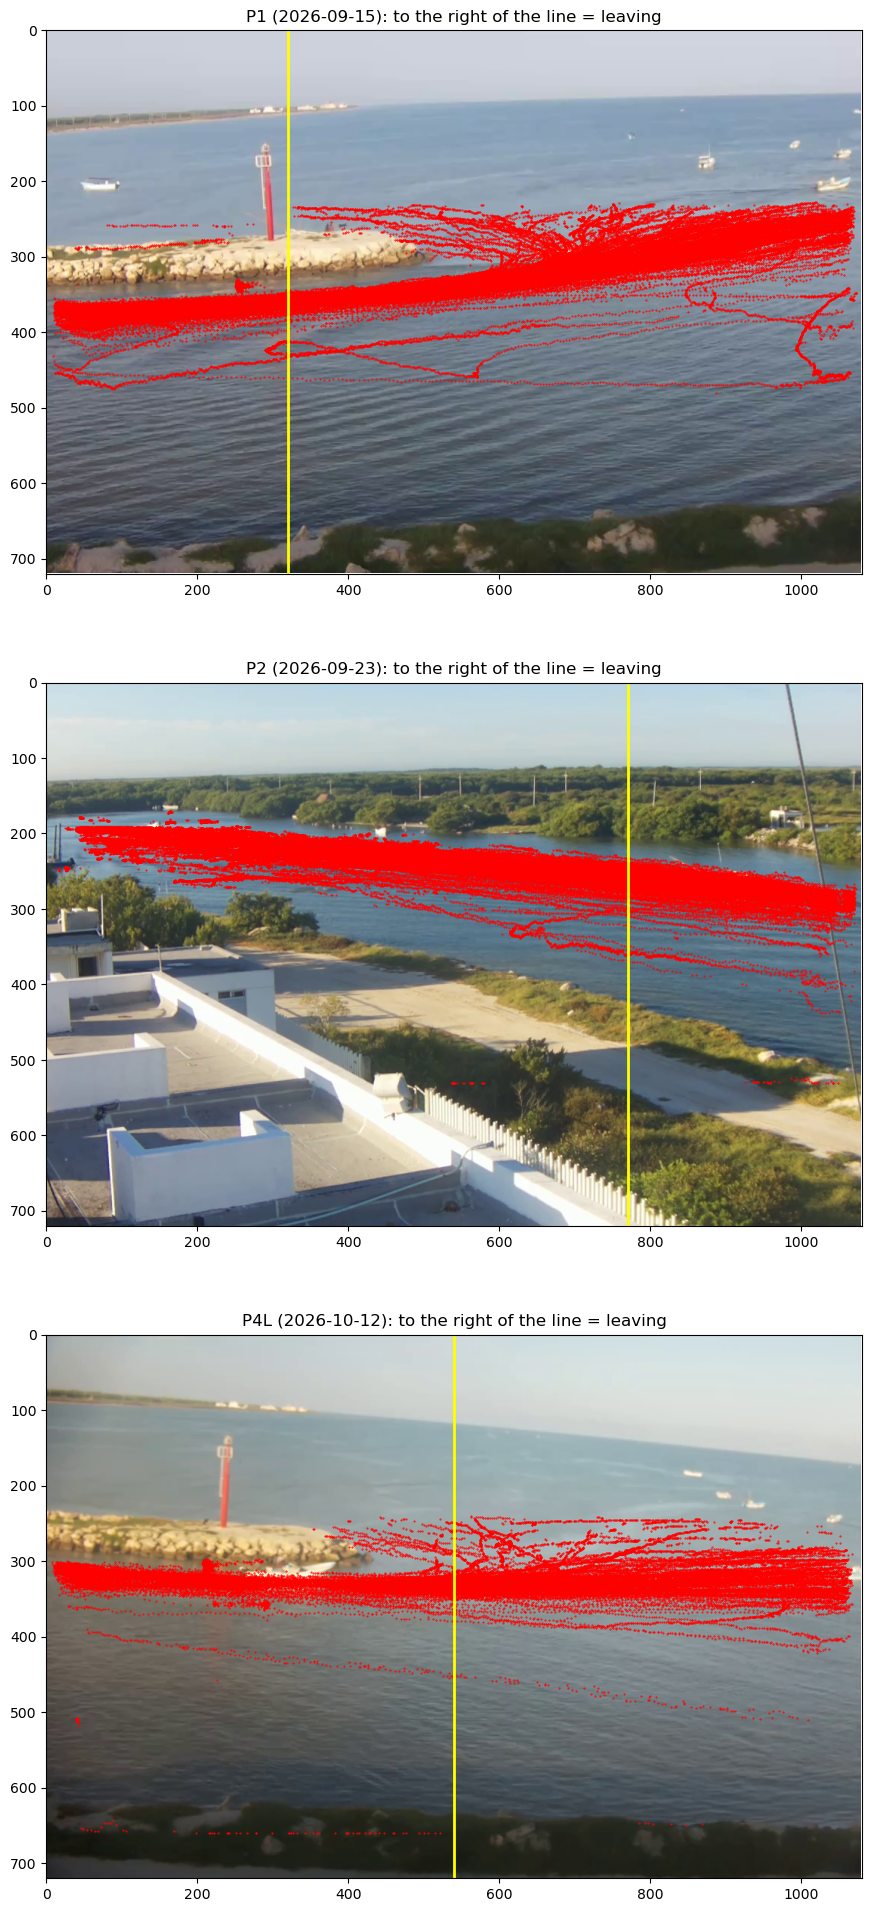

In [8]:
ENTRANCE = {
    "P1": {"x": 320, "right_is": "leaving"},
    "P2": {"x": 770, "right_is": "leaving"},
    "P4L": {"x": 540, "right_is": "leaving"},
}

fig, axes = plt.subplots(len(ENTRANCE), 1, figsize=(12, 8 * len(ENTRANCE)))
for ax, camera in zip(np.atleast_1d(axes), ENTRANCE):
    date, _, file = next(r for r in RUNS if r[1] == camera)
    video_name = "_".join(file.split("_")[1:5]).removesuffix(".csv") + ".mp4"   # s_P1_RAW_15-09_0530-1830.csv -> P1_RAW_15-09_0530-1830.mp4
    cap = cv2.VideoCapture(os.path.join(DRIVE, date, video_name))
    cap.set(cv2.CAP_PROP_POS_FRAMES, 60000)
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    day = data[(data["camera"] == camera) & (data["date"] == date)]
    ax.scatter(day["pixel_x"], day["pixel_y"], s=0.2, color="red")
    ax.axvline(ENTRANCE[camera]["x"], color="yellow", linewidth=2)
    ax.set_title(f"{camera} ({date}): to the right of the line = {ENTRANCE[camera]['right_is']}")
    ax.set_xlim(0, 1080)
    ax.set_ylim(720, 0)
plt.show()

In [9]:
def crossings(df, camera):
    # one row per track that crossed the line: time and direction
    line_x = ENTRANCE[camera]["x"]
    right_is = ENTRANCE[camera]["right_is"]
    left_is = "entering" if right_is == "leaving" else "leaving"

    rows = []
    tracks = df[(df["camera"] == camera) & (df["track_id"] >= 0)]
    for (date, track_id), t in tracks.groupby(["date", "track_id"]):
        if len(t) < MIN_POINTS:
            continue
        t = t.sort_values("frame")
        starts_right = t["pixel_x"].iloc[0] >= line_x
        ends_right = t["pixel_x"].iloc[-1] >= line_x
        if starts_right == ends_right:
            continue
        on_end_side = (t["pixel_x"] >= line_x) == ends_right
        crossed_at = t.loc[on_end_side, "time"].iloc[0]
        rows.append({"date": date, "camera": camera, "track_id": track_id,
                     "direction": right_is if ends_right else left_is, "time": crossed_at})
    return pd.DataFrame(rows)


passages = pd.concat([crossings(data, camera) for camera in ENTRANCE])
passages.to_csv("port_passages.csv", index=False)

print(passages.pivot_table(index=["date", "camera"], columns="direction", values="track_id", aggfunc="count", fill_value=0))

direction          entering  leaving
date       camera                   
2026-09-15 P1           171      254
2026-09-21 P1            61       97
2026-09-23 P2           236      256
2026-09-24 P2           272      254
2026-09-25 P2           228      276
2026-09-26 P2           267      266
2026-09-27 P2            98      109
2026-09-28 P2            45      135
2026-10-12 P4L          108      184
2026-10-13 P4L          194      287
2026-10-14 P4L          232      270
2026-10-15 P4L          197      308
2026-10-16 P4L          234      292
2026-10-17 P4L          215      279


Average number of boats per day entering and leaving, per time of day.
If a track breaks in two exactly at the line, the boat can be counted twice.

Average over 14 days (P1, P2, P4L):
  entering: 182.7 boats/day
  leaving: 233.4 boats/day


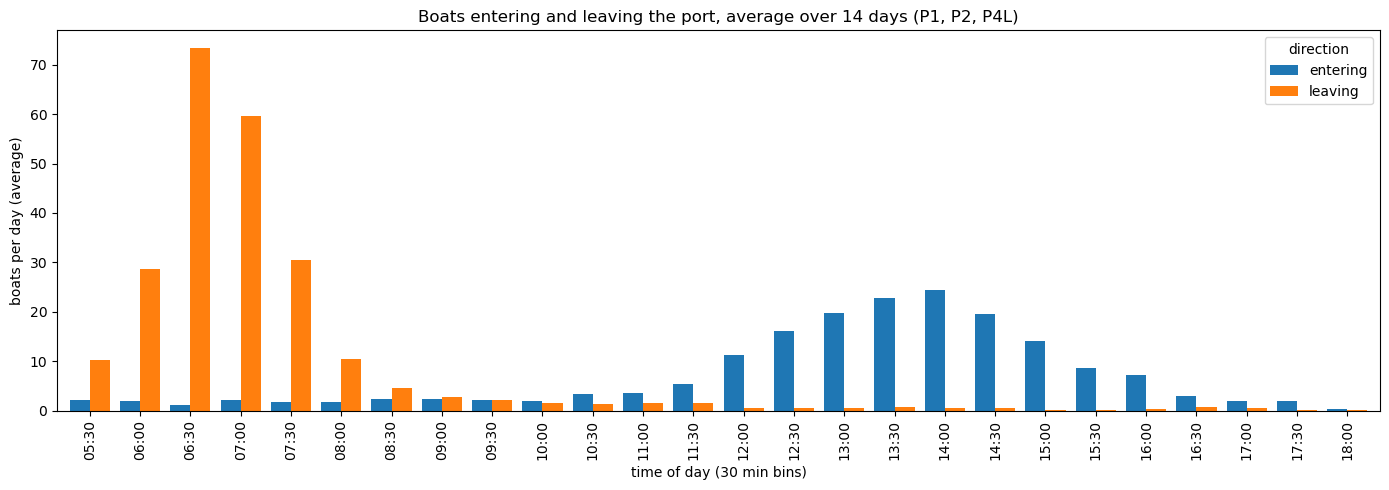

In [10]:
BIN_MIN = 30     # minutes

passages["time_of_day"] = passages["time"].dt.floor(f"{BIN_MIN}min").dt.strftime("%H:%M")
days = passages["date"].nunique()
per_bin = passages.groupby(["time_of_day", "direction"]).size().unstack(fill_value=0) / days

per_day = passages.groupby(["date", "direction"]).size().unstack(fill_value=0)
print(f"Average over {days} days ({', '.join(ENTRANCE)}):")
for direction, value in per_day.mean().items():
    print(f"  {direction}: {value:.1f} boats/day")

ax = per_bin.plot.bar(figsize=(14, 5), width=0.8, color={"entering": "tab:blue", "leaving": "tab:orange"})
ax.set_xlabel(f"time of day ({BIN_MIN} min bins)")
ax.set_ylabel("boats per day (average)")
ax.set_title(f"Boats entering and leaving the port, average over {days} days ({', '.join(ENTRANCE)})")
plt.tight_layout()
plt.savefig("port_traffic_per_time.png", dpi=200)
plt.show()

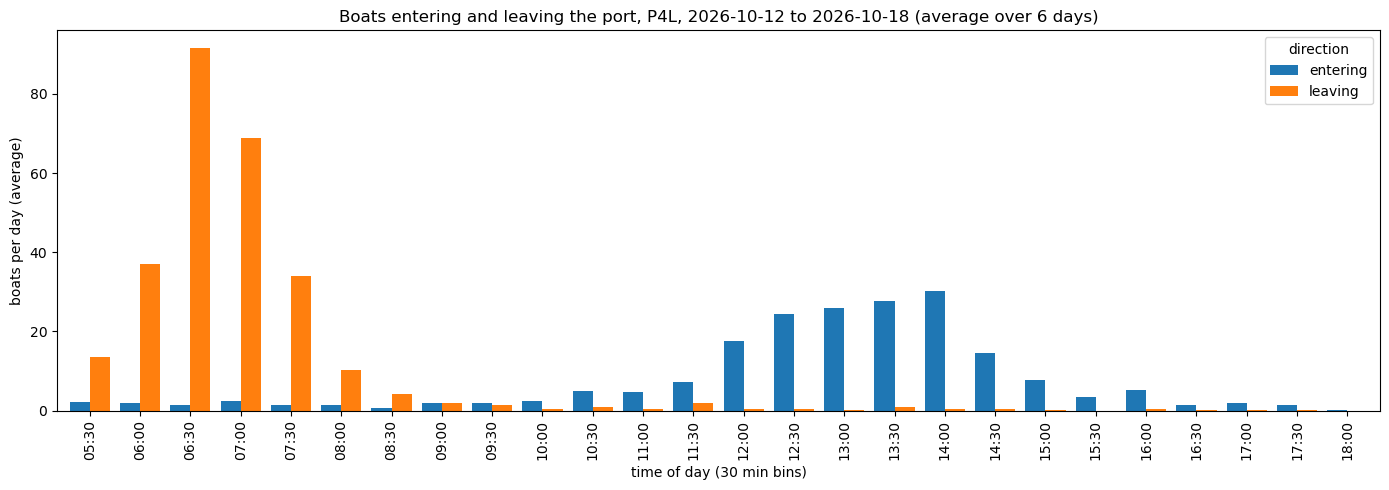

In [11]:
# same plot for one camera and a date range
CAMERA = "P4L"
START, END = "2026-10-12", "2026-10-18"

p = passages[(passages["camera"] == CAMERA) & (passages["date"] >= START) & (passages["date"] <= END)]
days_p = p["date"].nunique()
per_bin_p = p.groupby(["time_of_day", "direction"]).size().unstack(fill_value=0) / days_p

ax = per_bin_p.plot.bar(figsize=(14, 5), width=0.8, color={"entering": "tab:blue", "leaving": "tab:orange"})
ax.set_xlabel(f"time of day ({BIN_MIN} min bins)")
ax.set_ylabel("boats per day (average)")
ax.set_title(f"Boats entering and leaving the port, {CAMERA}, {START} to {END} (average over {days_p} days)")
plt.tight_layout()
plt.savefig(f"port_traffic_per_time_{CAMERA}_{START}_{END}.png", dpi=200)
plt.show()

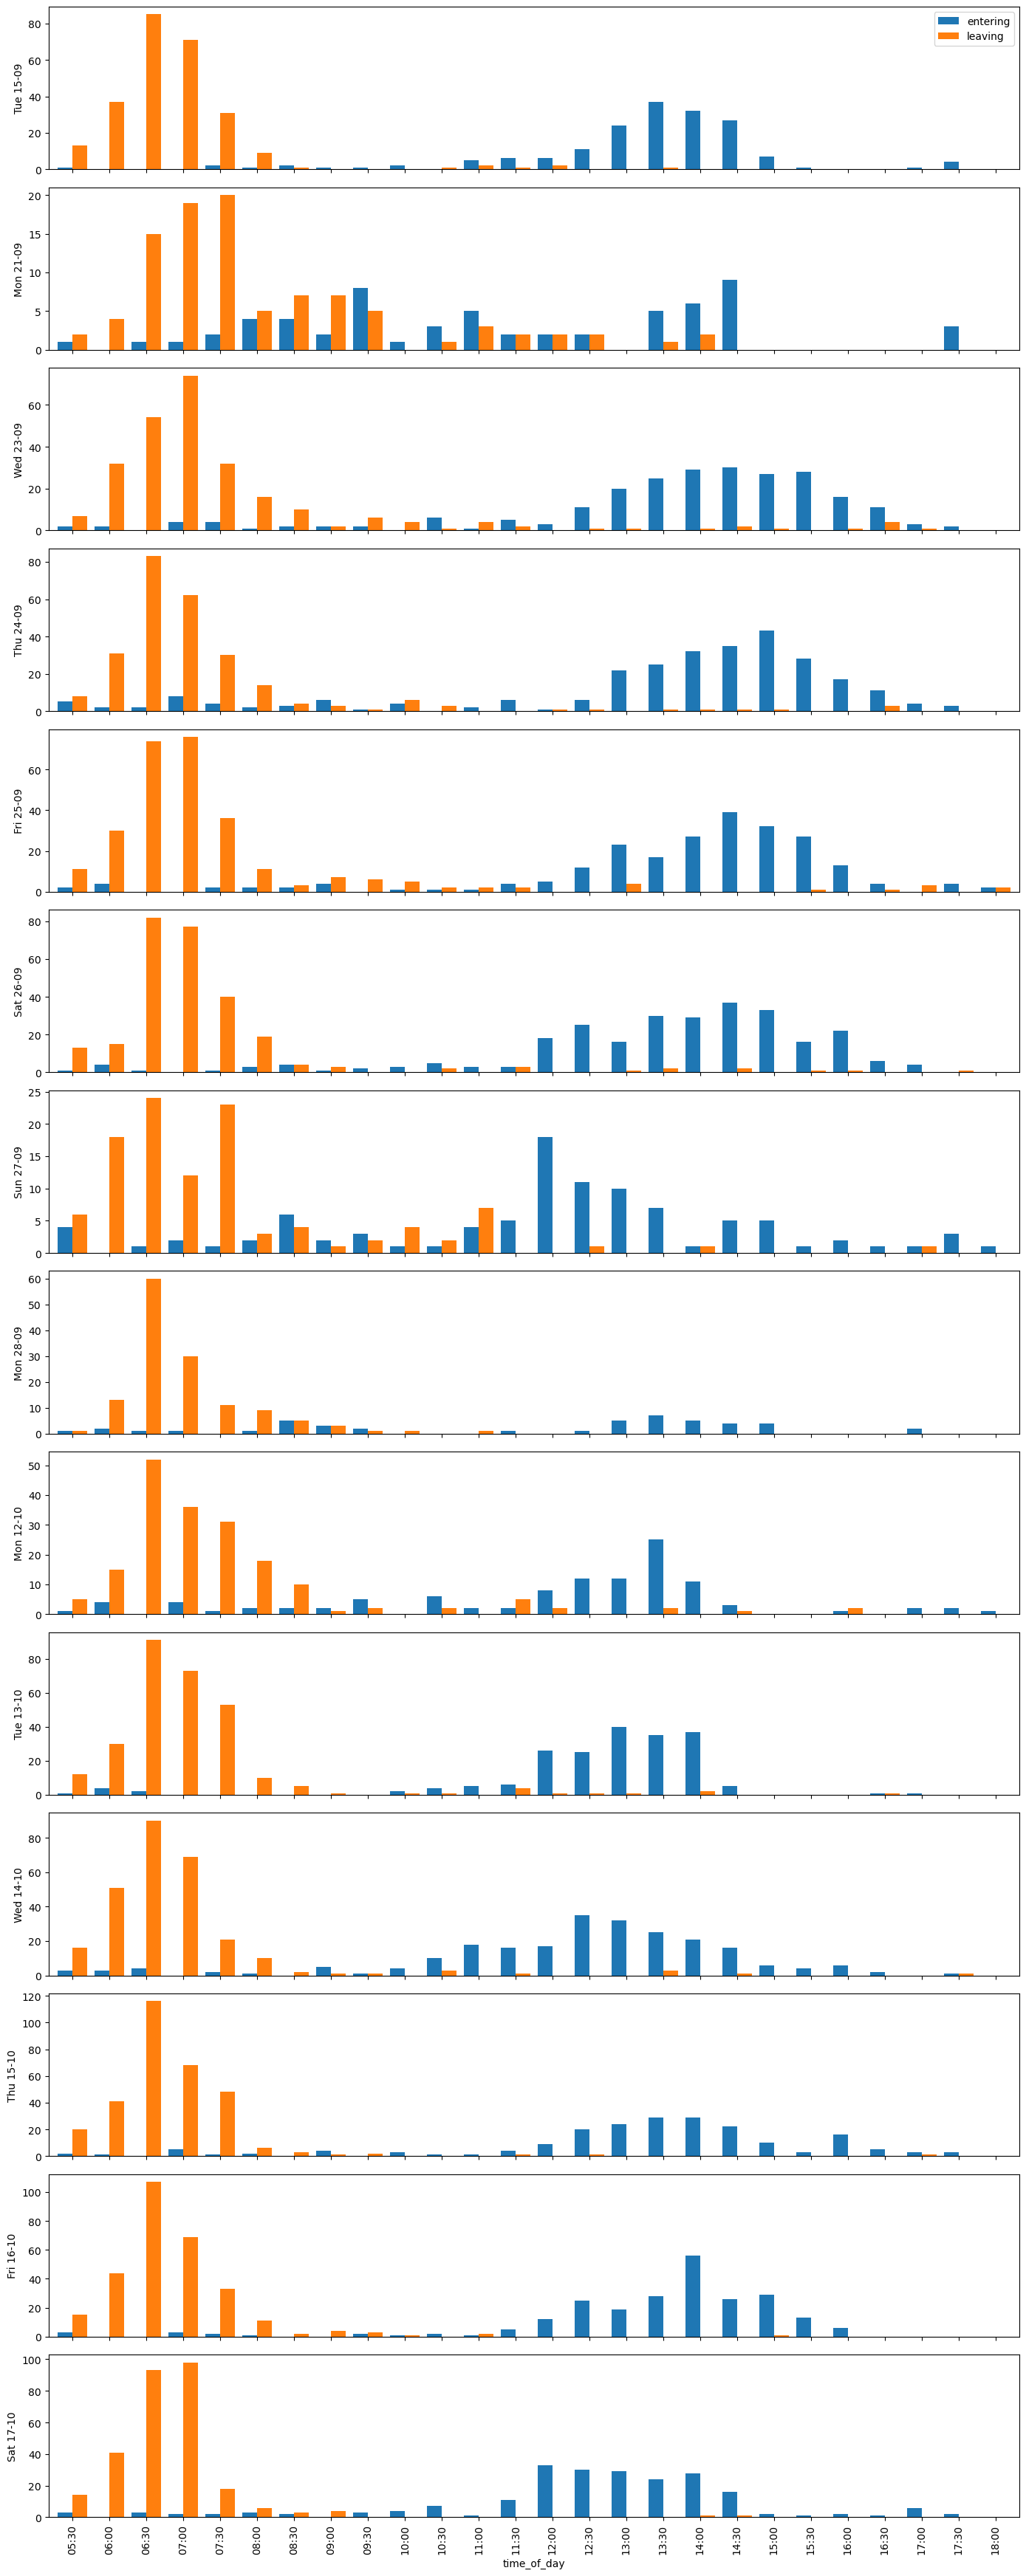

In [12]:
# per day
dates = sorted(passages["date"].unique())
fig, axes = plt.subplots(len(dates), 1, figsize=(14, 2.5 * len(dates)), sharex=True)
for ax, date in zip(np.atleast_1d(axes), dates):
    p = passages[passages["date"] == date]
    counts = p.groupby(["time_of_day", "direction"]).size().unstack(fill_value=0).reindex(per_bin.index, fill_value=0)
    counts.plot.bar(ax=ax, width=0.8, legend=False, color={"entering": "tab:blue", "leaving": "tab:orange"})
    ax.set_ylabel(pd.Timestamp(date).strftime("%a %d-%m"))
np.atleast_1d(axes)[0].legend(loc="upper right")
plt.tight_layout()
plt.show()